### Workspace for Matt

AI use declaration, code was formulated and written by me unless stated otherwise. AI was used to proofread, help debug and improve readability of code as well as to aid in adding desired aesthetic features on plots.

## Data load, clean and match

In [30]:
from pathlib import Path
import pandas as pd
import numpy as np

# Find the data folder
data_dir = Path('data') if Path('data').exists() else Path('../Data_Raw')
if not data_dir.exists():
    data_dir = Path('Data_Raw')

# Load the catalogues
Harris1 = pd.read_csv(data_dir / 'HarrisPartI.csv', na_values=['NA', 'XXXX', 'NONE'])
Harris3 = pd.read_csv(data_dir / 'HarrisPartIII.csv', na_values=['NA', 'XXXX', 'NONE'])
vandenBerg = pd.read_csv(data_dir / 'vandenBerg_table2.csv', na_values=['NA', 'XXXX', 'NONE'])
Krause = pd.read_csv(data_dir / 'Krause21.csv', na_values=['NA', 'XXXX', 'NONE'])

# Remove # from the NGC column name
vandenBerg.columns = [col.lstrip('#') for col in vandenBerg.columns]

# Lowercase aliases
harris1, harris3, vandenberg, krause = Harris1, Harris3, vandenBerg, Krause

# Test statements
print(f"Harris1.ID[4] = '{Harris1.ID[3]}'")
print(f"Loaded shapes: Harris1 {Harris1.shape}, Harris3 {Harris3.shape}, vandenBerg {vandenBerg.shape}, Krause {Krause.shape}")


Harris1.ID[4] = 'Whiting 1'
Loaded shapes: Harris1 (157, 11), Harris3 (157, 13), vandenBerg (55, 13), Krause (61, 8)


In [31]:
"""Run after prev cell.

Creates master and match_report.
"""
import re
from collections import defaultdict

# Name aliases
NAME_MAP = {
    'RUPRECHT106': 'RUP106',
    'PALOMAR12': 'PAL12',
    'TER8': 'TERZAN8',
}

# Remove spaces, standardise case and resolve aliases
def normalise_name(value):
    if pd.isna(value):
        return None
    key = re.sub(r'\s+', '', str(value)).upper()
    if key in {'', 'NA', 'NAN', 'NONE', 'XXXX'}:
        return None
    return NAME_MAP.get(key, key)

# Read the NGC number
def ngc_number(value, bare_number=False):
    key = normalise_name(value)
    if key is None:
        return pd.NA
    pattern = r'(\d+)(?:\.0+)?' if bare_number else r'NGC(\d+)'
    found = re.fullmatch(pattern, key)
    return int(found.group(1)) if found else pd.NA

# Copy sources
sources = {
    'h1': Harris1.copy(),
    'h3': Harris3.copy(),
    'k': Krause.copy(),
    'vb': vandenBerg.copy(),
}
sources['vb'] = sources['vb'].rename(columns={'#NGC': 'NGC'})
primary_column = {'h1': 'ID', 'h3': 'ID', 'k': 'Object', 'vb': 'NGC'}
alias_column = {'h1': 'Name', 'h3': None, 'k': 'AltName', 'vb': 'Name'}

for source, frame in sources.items():
    if not frame.columns.is_unique:
        raise ValueError(f'{source}: duplicate column names need review.')
    original = frame[primary_column[source]]
    numbers = original.map(lambda x: ngc_number(x, bare_number=(source == 'vb')))
    # Use nullable integers for NGC numbers

    frame['NGC'] = pd.array(numbers, dtype='Int64')

# Match against Harris IDs and alternative names
harris_lookup = defaultdict(set)
display_names = {}
for _, row in sources['h1'].iterrows():
    if normalise_name(row['ID']) is None:
        raise ValueError('Harris I contains a missing primary ID.')
    cluster_id = str(row['ID']).strip()
    if cluster_id in display_names:
        raise ValueError(f'Duplicate Harris I ID: {cluster_id}')
    display_names[cluster_id] = (
        str(row['Name']).strip() if normalise_name(row['Name']) else cluster_id
    )
    for value in [row['ID'], row['Name']]:
        key = normalise_name(value)
        if key is not None:
            harris_lookup[key].add(cluster_id)

def lookup_unique(key):
    candidates = harris_lookup.get(key, set())
    if len(candidates) > 1:
        raise ValueError(f'Ambiguous Harris name {key!r}: {sorted(candidates)}')
    return next(iter(candidates)) if candidates else None

records = []
indexed_sources = {}
for source, frame in sources.items():
    common_ids = []
    for row_position, (_, row) in enumerate(frame.iterrows()):
        number = row['NGC']
        primary = row[primary_column[source]]
        alias = row[alias_column[source]] if alias_column[source] else pd.NA
        primary_key = (
            f'NGC{number}' if pd.notna(number) else
            normalise_name(alias if source == 'vb' else primary)
        )
        alias_key = normalise_name(alias)
        primary_match = lookup_unique(primary_key)
        alias_match = lookup_unique(alias_key)

        if primary_match and alias_match and primary_match != alias_match:
            raise ValueError(f'{source} row {row_position}: ID and alias disagree.')
        if pd.notna(number) and alias_match:
            if normalise_name(alias_match) != f'NGC{number}':
                raise ValueError(f'{source} row {row_position}: NGC number conflicts with alias.')

        cluster_id = primary_match or alias_match
        if cluster_id:
            method = 'NGC' if pd.notna(number) and primary_match else (
                'primary name' if primary_match else 'Harris alias'
            )
        else:
            # Keep unmatched objects separate by source
            label = primary_key or alias_key or f'ROW{row_position}'
            cluster_id = f'UNMATCHED:{source}:{label}'
            method = 'unmatched - review'
            display_names[cluster_id] = (
                str(alias).strip() if normalise_name(alias) else
                str(primary).strip() if normalise_name(primary) else cluster_id
            )

        common_ids.append(cluster_id)
        records.append({
            'source': source, 'source_row': row_position,
            'original_id': primary, 'original_alias': alias,
            'cluster_id': cluster_id, 'NGC': number, 'match_method': method,
        })

    if pd.Index(common_ids).has_duplicates:
        repeated = pd.Series(common_ids)[pd.Series(common_ids).duplicated(keep=False)]
        raise ValueError(f'{source}: multiple rows map to one object; review {repeated.tolist()}')
    frame.index = pd.Index(common_ids, name='cluster_id')
    indexed_sources[source] = frame

# Keep and combine all data from original sources
master = pd.concat(indexed_sources, axis=1, join='outer', sort=False)
master.columns.names = ['source', 'quantity']

match_report = pd.DataFrame(records)
match_report['NGC'] = pd.array(match_report['NGC'], dtype='Int64')
meta = pd.DataFrame(index=master.index)
meta['cluster_id'] = master.index.astype('string')
meta['preferred_name'] = pd.Series(display_names, dtype='string').reindex(master.index)
meta['NGC'] = pd.Series(pd.NA, index=master.index, dtype='Int64')
for frame in indexed_sources.values():
    meta['NGC'] = meta['NGC'].fillna(frame['NGC'].reindex(master.index))
meta['matched_to_harris'] = master.index.isin(sources['h1']['ID'].str.strip())
meta.columns = pd.MultiIndex.from_product([['meta'], meta.columns], names=['source', 'quantity'])
master = pd.concat([meta, master], axis=1)

print(f'Master table: {len(master)} clusters, {master.shape[1]} columns')
print('\nMatching summary:')
print(pd.crosstab(match_report['source'], match_report['match_method']).to_string())
unmatched = match_report[match_report['match_method'] == 'unmatched - review']
print('\nUnmatched rows (retained in master):')
print(unmatched[['source', 'original_id', 'original_alias', 'cluster_id']].to_string(index=False))

# Access examples
# master['h1']  # Harris I
# master['h3']['v_r']  # Radial velocities
# master.loc['NGC 104', ('vb', 'Age')]  # One measurement
# master['meta']['NGC']  # NGC numbers
# master[[('vb', 'Age'), ('vb', 'FeH')]].dropna()  # Complete AMR rows


Master table: 158 clusters, 52 columns

Matching summary:
match_method  NGC  primary name  unmatched - review
source                                             
h1            104            53                   0
h3            104            53                   0
k              58             3                   0
vb             52             2                   1

Unmatched rows (retained in master):
source original_id original_alias         cluster_id
    vb        <NA>          Arp21 UNMATCHED:vb:ARP21


In [32]:
# Save the master catalogue
master.to_csv(data_dir / "master_catalogue.csv", index=True)
""" example on how to load csv
master = pd.read_csv(
    data_dir / "master_catalogue.csv",
    header=[0, 1],
    index_col=0
)

# Restore nullable integer types for NGC numbers
for source in ["meta", "h1", "h3", "k", "vb"]:
    master[(source, "NGC")] = master[(source, "NGC")].astype("Int64")

"""

' example on how to load csv\nmaster = pd.read_csv(\n    data_dir / "master_catalogue.csv",\n    header=[0, 1],\n    index_col=0\n)\n\n# Restore nullable integer types for NGC numbers\nfor source in ["meta", "h1", "h3", "k", "vb"]:\n    master[(source, "NGC")] = master[(source, "NGC")].astype("Int64")\n\n'

Select the comparison sample

Require age, metallicity, Galactocentric distance and LSR velocity. Use VandenBerg ages and metallicities, with missing values filled from Krause.
Filter out maximally informative data points for analysis, if includes age + Fe/H + R_gc + v_LSR data. Prioritises VandenBerg Data since it includes error and uses better method.

In [33]:
from pathlib import Path
import pandas as pd

# Find the master catalogue
for p in [Path('data'), Path('PHYS3116_Larawag/data'), Path('../data')]:
    if (p / 'master_catalogue.csv').exists():
        data_dir = p
        break

# Load the table and strip spaces from labels
master_raw = pd.read_csv(data_dir / 'master_catalogue.csv', header=[0, 1], index_col=0, dtype=str, encoding='utf-8')
master_raw.columns = pd.MultiIndex.from_tuples([(c[0].strip(), c[1].strip()) for c in master_raw.columns], names=['source', 'quantity'])
master_raw.index = master_raw.index.str.strip()
master_raw.index.name = 'cluster_id'

# Convert age and metallicity to numbers
age_vb = pd.to_numeric(master_raw[('vb', 'Age')], errors='coerce')
age_k  = pd.to_numeric(master_raw[('k', 'Age')], errors='coerce')
feh_vb = pd.to_numeric(master_raw[('vb', 'FeH')], errors='coerce')
feh_k  = pd.to_numeric(master_raw[('k', 'FeH')], errors='coerce')

# Use VandenBerg values, then fill gaps from Krause
age = age_vb.combine_first(age_k)
feh = feh_vb.combine_first(feh_k)

# Use Harris distances, with VandenBerg as a fallback
rgc   = pd.to_numeric(master_raw[('h1', 'R_gc')], errors='coerce').combine_first(pd.to_numeric(master_raw[('vb', 'R_G')], errors='coerce'))
v_lsr = pd.to_numeric(master_raw[('h3', 'v_LSR')], errors='coerce')

# Require age, metallicity, distance and velocity
mask_63 = age.notna() & feh.notna() & rgc.notna() & v_lsr.notna()

# Save the filtered catalogue
filtered_catalogue = master_raw.loc[mask_63]
out_path = data_dir / 'filtered_catalogue.csv'
filtered_catalogue.to_csv(out_path, encoding='utf-8')

print(f"Successfully filtered {len(filtered_catalogue)} clusters and saved to: {out_path}")


Successfully filtered 63 clusters and saved to: data\filtered_catalogue.csv


## Data Visualisation

### Exploratory

3D plot of age metalicity galactic distance for visualisation purposes
(AI assisted code for this experiment as was not sure if I would purue it further, which I didn't)

In [13]:
import plotly.graph_objects as go
from pathlib import Path
import pandas as pd
import numpy as np

# 1. Load master catalogue if not already in session
if 'master' not in globals():
    data_dir = Path('data') if Path('data').exists() else Path('../Data_Raw')
    master = pd.read_csv(
        data_dir / 'master_catalogue.csv',
        header=[0, 1],
        index_col=0
    )

# 2. Extract VandenBerg et al. (2013) data (Circles)
vb_mask = master[('vb', 'Age')].notna() & master[('vb', 'FeH')].notna()
df_vb = master.loc[vb_mask].copy()

feh_vb = df_vb[('vb', 'FeH')].astype(float)
age_vb = df_vb[('vb', 'Age')].astype(float)
rg_vb = df_vb[('vb', 'R_G')].fillna(df_vb[('h1', 'R_gc')]).astype(float)
names_vb = df_vb[('meta', 'preferred_name')].fillna(df_vb.index.to_series())

# 3. Extract Krause et al. (2021) data (Squares)
k_mask = master[('k', 'Age')].notna() & master[('k', 'FeH')].notna()
df_k = master.loc[k_mask].copy()

feh_k = df_k[('k', 'FeH')].astype(float)
age_k = df_k[('k', 'Age')].astype(float)
rg_k = df_k[('h1', 'R_gc')].astype(float)
names_k = df_k[('meta', 'preferred_name')].fillna(df_k.index.to_series())

# 4. Construct 3D Interactive Plot
fig = go.Figure()

# Trace 1: VandenBerg 
fig.add_trace(go.Scatter3d(
    x=feh_vb,
    y=rg_vb,
    z=age_vb,
    mode='markers',
    name='VandenBerg et al. (2013)',
    text=names_vb,
    hovertemplate=(
        '<b>%{text}</b><br>' +
        'Metallicity [Fe/H]: %{x:.2f} dex<br>' +
        'Galactocentric Dist R_gc: %{y:.1f} kpc<br>' +
        'Age: %{z:.2f} Gyr' +
        '<extra>VandenBerg</extra>'
    ),
    marker=dict(
        size=6,
        symbol='circle',
        color='#2563eb',  # Vibrant blue
        opacity=0.85,
        line=dict(color='#1e3a8a', width=1)
    )
))

# Trace 2: Krause 
fig.add_trace(go.Scatter3d(
    x=feh_k,
    y=rg_k,
    z=age_k,
    mode='markers',
    name='Krause et al. (2021)',
    text=names_k,
    hovertemplate=(
        '<b>%{text}</b><br>' +
        'Metallicity [Fe/H]: %{x:.2f} dex<br>' +
        'Galactocentric Dist R_gc: %{y:.1f} kpc<br>' +
        'Age: %{z:.2f} Gyr' +
        '<extra>Krause</extra>'
    ),
    marker=dict(
        size=6,
        symbol='square',
        color='#ef4444',  # Vibrant red/coral
        opacity=0.85,
        line=dict(color='#991b1b', width=1)
    )
))

# 5. Configure 3D Axes, Camera Angle, and Layout
fig.update_layout(
    title=dict(
        text='<b>3D Globular Cluster Space: Metallicity vs. Distance vs. Age</b>',
        x=0.5,
        y=0.95,
        font=dict(size=15)
    ),
    scene=dict(
        xaxis=dict(
            title='Metallicity [Fe/H] (dex)',
            backgroundcolor='rgba(240, 244, 248, 0.4)',
            gridcolor='white'
        ),
        yaxis=dict(
            title='Galactocentric Distance R_gc (kpc)',
            backgroundcolor='rgba(240, 244, 248, 0.4)',
            gridcolor='white'
        ),
        zaxis=dict(
            title='Age (Gyr)',
            backgroundcolor='rgba(240, 244, 248, 0.4)',
            gridcolor='white'
        ),
        camera=dict(
            eye=dict(x=1.7, y=-1.7, z=1.2)  # Initial 3D isometric view
        ),
        aspectmode='manual',
        aspectratio=dict(x=1.2, y=1.2, z=1.0)
    ),
    legend=dict(
        x=0.02,
        y=0.98,
        bgcolor='rgba(255, 255, 255, 0.85)',
        bordercolor='#cbd5e1',
        borderwidth=1
    ),
    margin=dict(l=0, r=0, b=0, t=40)
)

fig.show()


Not very clear, see plot_3d_amr.m, matlab code for better plot

### Age Metalicity


Shows vandenberg and krause data for comparison with colorbar showing galactic distance

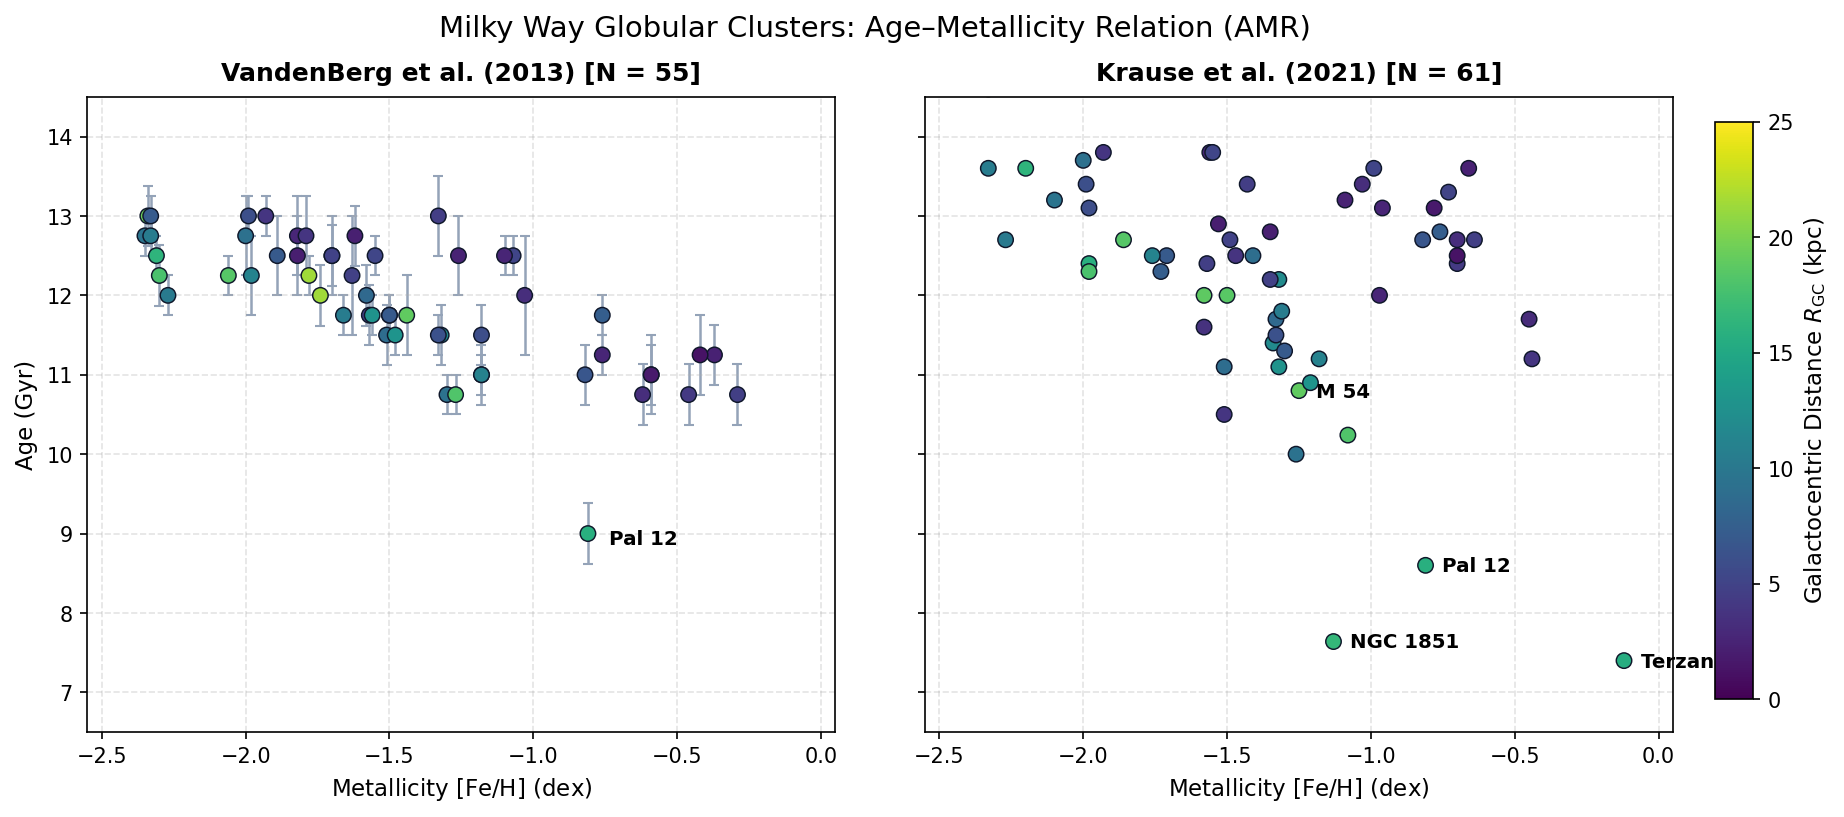

In [34]:
import matplotlib.pyplot as plt
from pathlib import Path
import pandas as pd
import numpy as np
if 'master' not in globals():
    data_dir = Path('data') if Path('data').exists() else Path('../Data_Raw')
    master = pd.read_csv(data_dir / 'master_catalogue.csv', header=[0, 1], index_col=0)
# Select rows with age and metallicity
vb_mask = master[('vb', 'Age')].notna() & master[('vb', 'FeH')].notna()
df_vb = master.loc[vb_mask].copy()
k_mask = master[('k', 'Age')].notna() & master[('k', 'FeH')].notna()
df_k = master.loc[k_mask].copy()
names_k = df_k[('meta', 'preferred_name')].fillna(df_k.index.to_series())
names_vb = df_vb[('meta', 'preferred_name')].fillna(df_vb.index.to_series())
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5), dpi=150, sharey=True)
# VandenBerg panel
ax1.errorbar(
    df_vb[('vb', 'FeH')].astype(float), df_vb[('vb', 'Age')].astype(float),
    yerr=df_vb[('vb', 'Age_err')].astype(float),
    fmt='none', ecolor='#94a3b8', elinewidth=1.2, capsize=2.5, zorder=1
)
sc1 = ax1.scatter(
    df_vb[('vb', 'FeH')].astype(float), df_vb[('vb', 'Age')].astype(float),
    c=df_vb[('vb', 'R_G')].fillna(df_vb[('h1', 'R_gc')]).astype(float),
    cmap='viridis', s=55, edgecolors='#0f172a', linewidths=0.7, zorder=2, vmin=0, vmax=25
)
ax1.set_title(f'VandenBerg et al. (2013) [N = {len(df_vb)}]', fontsize=12, fontweight='bold', pad=8)
ax1.set_xlabel(r'Metallicity $\mathrm{[Fe/H]}$ (dex)', fontsize=11)
ax1.set_ylabel(r'Age (Gyr)', fontsize=11)
ax1.set_xlim(-2.55, 0.05)
ax1.set_ylim(6.5, 14.5)
ax1.grid(True, linestyle='--', alpha=0.35)
p12 = df_vb[names_vb == 'Pal 12']
if not p12.empty:
    ax1.annotate('Pal 12', (float(p12[('vb', 'FeH')].iloc[0]), float(p12[('vb', 'Age')].iloc[0])),
                 xytext=(10, -5), textcoords='offset points', fontsize=9.5, fontweight='bold')
# Krause panel
sc2 = ax2.scatter(
    df_k[('k', 'FeH')].astype(float), df_k[('k', 'Age')].astype(float),
    c=df_k[('h1', 'R_gc')].astype(float),
    cmap='viridis', s=55, edgecolors='#0f172a', linewidths=0.7, zorder=2, vmin=0, vmax=25
)
ax2.set_title(f'Krause et al. (2021) [N = {len(df_k)}]', fontsize=12, fontweight='bold', pad=8)
ax2.set_xlabel(r'Metallicity $\mathrm{[Fe/H]}$ (dex)', fontsize=11)
ax2.set_xlim(-2.55, 0.05)
ax2.grid(True, linestyle='--', alpha=0.35)
for name in ['Terzan 7', 'Pal 12', 'NGC 1851', 'M 54']:
    m = df_k[names_k == name]
    if not m.empty:
        ax2.annotate(name, (float(m[('k', 'FeH')].iloc[0]), float(m[('k', 'Age')].iloc[0])),
                     xytext=(8, -3), textcoords='offset points', fontsize=9.5, fontweight='bold')
# Shared colour bar
fig.subplots_adjust(right=0.88, wspace=0.12)
cbar_ax = fig.add_axes([0.90, 0.15, 0.018, 0.7])
cbar = fig.colorbar(sc2, cax=cbar_ax)
cbar.set_label(r'Galactocentric Distance $R_{\mathrm{GC}}$ (kpc)', fontsize=11)
fig.suptitle('Milky Way Globular Clusters: Age–Metallicity Relation (AMR)', fontsize=14, y=0.98)
plt.show()



Will peformed analysis on this part, will use his graphs

### Kinematics
Want to use line of sight velocities to estimate orbital information


In [36]:
from pathlib import Path
import numpy as np
import pandas as pd

# Cluster data and catalogue access

class gc_kinematics:
    """Stores kinematic and spatial quantities for an individual globular cluster."""
    def __init__(self, ID, v_gsr, x, y, z, p, R_gc=None, R_cyl=None, v_lsr=None,
                 resid=None, V_rot=None, sigma_V=None):
        self.ID = ID  # Cluster ID
        self.v_gsr = v_gsr  # GSR line-of-sight velocity (km/s)
        self.x = x  # Galactocentric x (kpc); Sun at -8
        self.y = y  # Galactocentric y (kpc)
        self.z = z  # Height above the Galactic plane (kpc)
        self.p = p  # Projection factor
        self.R_gc = R_gc  # Galactocentric distance (kpc)
        self.R_cyl = R_cyl  # Cylindrical radius (kpc)
        self.v_lsr = v_lsr  # LSR velocity (km/s)

        # Rotation fit
        self.resid = resid  # v_gsr - V_rot * p (km/s)
        self.V_rot = V_rot  # Fitted mean rotation (km/s)
        self.sigma_V = sigma_V  # Standard error (km/s)
    def __getitem__(self, idx):
        """Allows positional index access: [0]=ID, [1]=v_gsr, [2]=x, [3]=y, [4]=z, [5]=p, [6]=resid."""
        fields = [self.ID, self.v_gsr, self.x, self.y, self.z, self.p, self.resid, self.V_rot, self.sigma_V]
        return fields[idx]
    def __repr__(self):
        r_str = f"{self.resid:.1f}" if self.resid is not None else "None"
        return (f"gc_kinematics(ID='{self.ID}', v_gsr={self.v_gsr:.1f} km/s, "
                f"x={self.x:.2f}, y={self.y:.2f}, z={self.z:.2f}, p={self.p:.3f}, resid={r_str})")

class KinematicsCatalogue:
    """
    Hybrid container for gc_kinematics instances.
    Supports:
      - Positional index:  kinematics_catalogue[0]
      - String key lookup: kinematics_catalogue['NGC 104'] or kinematics_catalogue['NGC104']
      - Dot attribute:     kinematics_catalogue.NGC_104 or kinematics_catalogue.NGC104
      - Standard loops:    for gc in kinematics_catalogue: ...
    """
    def __init__(self):
        self._list = []
        self._dict = {}

    def append(self, item):
        self._list.append(item)
        key_raw = str(item.ID).strip()
        key_norm = key_raw.replace(' ', '').upper()
        key_attr = key_raw.replace(' ', '_').replace('-', '_')

        # Allow lookup by ID or alias
        self._dict[key_raw] = item
        self._dict[key_norm] = item
        self._dict[key_attr] = item

        # Allow attribute access
        setattr(self, key_attr, item)
        if key_norm != key_attr:
            setattr(self, key_norm, item)

    def __getitem__(self, key):
        if isinstance(key, (int, slice)):
            return self._list[key]
        elif isinstance(key, str):
            k = key.strip()
            if k in self._dict:
                return self._dict[k]
            k_norm = k.replace(' ', '').upper()
            if k_norm in self._dict:
                return self._dict[k_norm]
            raise KeyError(f"Cluster '{key}' not found in kinematics catalogue.")
        raise TypeError(f"Invalid key type: {type(key)}")

    def __len__(self):
        return len(self._list)

    def __iter__(self):
        return iter(self._list)

    def to_dataframe(self):
        """Export as a clean pandas DataFrame."""
        return pd.DataFrame([{
            'ID': gc.ID,
            'v_gsr': gc.v_gsr,
            'x': gc.x,
            'y': gc.y,
            'z': gc.z,
            'p': gc.p,
            'R_gc': gc.R_gc,
            'R_cyl': gc.R_cyl,
            'v_lsr': gc.v_lsr
        } for gc in self._list])

# Load the master catalogue

for p in [Path('data'), Path('PHYS3116_Larawag/data'), Path('../data')]:
    if (p / 'master_catalogue.csv').exists():
        data_dir = p
        break

master = pd.read_csv(data_dir / 'master_catalogue.csv', header=[0, 1], index_col=0, dtype=str, encoding='utf-8')
master.columns = pd.MultiIndex.from_tuples([(c[0].strip(), c[1].strip()) for c in master.columns])
master.index = master.index.str.strip()

# Solar circular speed (km/s)
v0 = 220.0

kinematics_catalogue = KinematicsCatalogue()

for cluster_id, row in master.iterrows():
    cid = str(cluster_id).strip()
    if cid in ['', 'cluster_id', 'nan', 'None']:
        continue

    # Read positions and velocities
    v_lsr_val = pd.to_numeric(row[('h3', 'v_LSR')], errors='coerce')
    L_val     = pd.to_numeric(row[('h1', 'L')], errors='coerce')
    B_val     = pd.to_numeric(row[('h1', 'B')], errors='coerce')
    X_val     = pd.to_numeric(row[('h1', 'X')], errors='coerce')
    Y_val     = pd.to_numeric(row[('h1', 'Y')], errors='coerce')
    Z_val     = pd.to_numeric(row[('h1', 'Z')], errors='coerce')
    R_Sun_val = pd.to_numeric(row[('h1', 'R_Sun')], errors='coerce')
    R_gc_val  = pd.to_numeric(row[('h1', 'R_gc')], errors='coerce')

    # Skip rows with missing values
    req_vals = [v_lsr_val, L_val, B_val, X_val, Y_val, Z_val, R_Sun_val, R_gc_val]
    if any(np.isnan(v) for v in req_vals):
        continue

    # Convert LSR velocity to GSR
    L_rad = np.radians(L_val)
    B_rad = np.radians(B_val)
    v_gsr = v_lsr_val + v0 * np.sin(L_rad) * np.cos(B_rad)

    # Move the origin to the Galactic centre
    x = X_val - 8.0
    y = Y_val
    z = Z_val

    # Radius in the Galactic plane
    R_cyl = np.sqrt(x**2 + y**2)

    # Project the prograde direction onto the line of sight
    if R_cyl > 0 and R_Sun_val > 0:
        eHat_phi = np.array([y, -x, 0.0]) / R_cyl
        eHat_los = np.array([X_val, Y_val, Z_val]) / R_Sun_val
        p = float(np.dot(eHat_phi, eHat_los))
    else:
        p = 0.0

    # Add the cluster to the catalogue
    gc = gc_kinematics(ID=cid, v_gsr=v_gsr, x=x, y=y, z=z, p=p, R_gc=R_gc_val, R_cyl=R_cyl, v_lsr=v_lsr_val)
    kinematics_catalogue.append(gc)

print(f"Successfully processed {len(kinematics_catalogue)} clusters into kinematics_catalogue.")
print(f" - Access example by index [0]:                {kinematics_catalogue[0]}")
print(f" - Access example by string ['NGC 104'].v_gsr: {kinematics_catalogue['NGC 104'].v_gsr:.2f} km/s")
print(f" - Access example by dot-attribute .NGC_104.p: {kinematics_catalogue.NGC_104.p:.3f}")


Successfully processed 143 clusters into kinematics_catalogue.
 - Access example by index [0]:                gc_kinematics(ID='NGC 104', v_gsr=-153.0 km/s, x=-6.10, y=-2.60, z=-3.10, p=-0.697, resid=None)
 - Access example by string ['NGC 104'].v_gsr: -152.97 km/s
 - Access example by dot-attribute .NGC_104.p: -0.697


In [38]:
# Compare calculated and catalogue distances

print("=" * 65)
print("TEST 1: Coordinate check: sqrt(x^2 + y^2 + z^2) vs R_gc (First 10)")
print("=" * 65)
print(f"{'ID':<12} {'R_gc (kpc)':<14} {'Calculated (kpc)':<18} {'Error (kpc)':<12}")
print("-" * 65)

for gc in kinematics_catalogue[:10]:
    calc_rgc = np.sqrt(gc.x**2 + gc.y**2 + gc.z**2)
    err = calc_rgc - gc.R_gc
    print(f"{gc.ID:<12} {gc.R_gc:<14.3f} {calc_rgc:<18.3f} {err:<+12.4f}")

print("\nNote: Tiny ~0.01 - 0.05 kpc discrepancies are expected due to rounding")
print("of Harris X, Y, Z coordinates to 1 decimal place.")

# Check the prograde direction at the Sun

print("\n" + "=" * 65)
print("TEST 2: Verify eHat_phi sign at Sun's position (x = -8, y = 0)")
print("=" * 65)

sun_x, sun_y = -8.0, 0.0
sun_R_cyl = np.sqrt(sun_x**2 + sun_y**2)
sun_eHat_phi = np.array([sun_y, -sun_x, 0.0]) / sun_R_cyl

print(f"Formula (y, -x, 0)/R_cyl at Sun gives: ({sun_eHat_phi[0]:.1f}, {sun_eHat_phi[1]:.1f}, {sun_eHat_phi[2]:.1f})")
assert np.allclose(sun_eHat_phi, [0.0, 1.0, 0.0]), "Error: eHat_phi must point in +Y direction!"
print("PASSED: Points in the +Y direction (direction of Solar/disk rotation).")

# AI used to generate code for shapeing test output


TEST 1: Coordinate check: sqrt(x^2 + y^2 + z^2) vs R_gc (First 10)
ID           R_gc (kpc)     Calculated (kpc)   Error (kpc) 
-----------------------------------------------------------------
NGC 104      7.400          7.320              -0.0802     
NGC 288      12.000         12.034             +0.0341     
NGC 362      9.400          9.405              +0.0053     
Whiting 1    34.500         34.545             +0.0455     
NGC 1261     18.100         18.133             +0.0334     
Pal 1        17.200         17.251             +0.0514     
AM 1         124.600        124.642            +0.0417     
Eridanus     95.000         94.998             -0.0022     
Pal 2        35.000         34.946             -0.0542     
NGC 1851     16.600         16.603             +0.0030     

Note: Tiny ~0.01 - 0.05 kpc discrepancies are expected due to rounding
of Harris X, Y, Z coordinates to 1 decimal place.

TEST 2: Verify eHat_phi sign at Sun's position (x = -8, y = 0)
Formula (y, -x, 0)/R_

In [39]:
# Fit v_GSR = V_rot * p through the origin

p_vals     = np.array([gc.p for gc in kinematics_catalogue])
v_gsr_vals = np.array([gc.v_gsr for gc in kinematics_catalogue])
N          = len(kinematics_catalogue)

# Fit slope
sum_p2     = np.sum(p_vals**2)
sum_p_vgsr = np.sum(p_vals * v_gsr_vals)
V_rot      = sum_p_vgsr / sum_p2

# Residuals from the fitted mean
resid_vals = v_gsr_vals - V_rot * p_vals

# Residual scatter; one fitted parameter
sigma_resid = np.sqrt(np.sum(resid_vals**2) / (N - 1))

# Standard error of the slope
sigma_V = sigma_resid / np.sqrt(sum_p2)

# Store the fit and residuals

for gc, r in zip(kinematics_catalogue, resid_vals):
    gc.resid   = float(r)
    gc.V_rot   = float(V_rot)
    gc.sigma_V = float(sigma_V)

# Store the catalogue-level fit
kinematics_catalogue.V_rot       = float(V_rot)
kinematics_catalogue.sigma_V     = float(sigma_V)
kinematics_catalogue.sigma_resid = float(sigma_resid)

# Fit results

print("=" * 65)
print("KINEMATIC FIT RESULTS (Least Squares Through Origin)")
print("=" * 65)
print(f"Number of clusters (N):          {N}")
print(f"Bulk Rotation Velocity (V_rot):   {V_rot:.2f} ± {sigma_V:.2f} km/s")
print(f"Velocity Dispersion (sigma_resid): {sigma_resid:.2f} km/s")
print("-" * 65)

print(f"Access via dot-notation: kinematics_catalogue.NGC_104.resid = {kinematics_catalogue.NGC_104.resid:+.1f} km/s")
print(f"Access via catalogue:    kinematics_catalogue.V_rot         = {kinematics_catalogue.V_rot:.2f} km/s")

# Show the ten largest absolute residuals
print("\n" + "=" * 65)
print("TOP KINEMATIC OUTLIERS (Candidates with Extreme Non-Circular Motion)")
print("=" * 65)
print(f"{'ID':<12} {'v_GSR (km/s)':<14} {'p':<10} {'V_rot*p (km/s)':<16} {'resid (km/s)':<14}")
print("-" * 65)

sorted_by_abs_resid = sorted(kinematics_catalogue, key=lambda gc: abs(gc.resid), reverse=True)
for gc in sorted_by_abs_resid[:10]:
    v_rot_p = gc.V_rot * gc.p
    print(f"{gc.ID:<12} {gc.v_gsr:<+14.1f} {gc.p:<+10.3f} {v_rot_p:<+16.1f} {gc.resid:<+14.1f}")

# Generative AI used to format text output

KINEMATIC FIT RESULTS (Least Squares Through Origin)
Number of clusters (N):          143
Bulk Rotation Velocity (V_rot):   73.75 ± 18.51 km/s
Velocity Dispersion (sigma_resid): 123.78 km/s
-----------------------------------------------------------------
Access via dot-notation: kinematics_catalogue.NGC_104.resid = -101.6 km/s
Access via catalogue:    kinematics_catalogue.V_rot         = 73.75 km/s

TOP KINEMATIC OUTLIERS (Candidates with Extreme Non-Circular Motion)
ID           v_GSR (km/s)   p          V_rot*p (km/s)   resid (km/s)  
-----------------------------------------------------------------
Djorg 1      -367.7         -0.083     -6.1             -361.6        
NGC 3201     +267.1         -0.888     -65.5            +332.7        
NGC 6287     -278.6         +0.000     +0.0             -278.6        
NGC 6934     -234.3         +0.511     +37.7            -271.9        
NGC 6981     -229.6         +0.430     +31.7            -261.3        
NGC 6101     +214.7         -0.498 

### Higher-projection sightlines
Select clusters with $|p| > 0.5$ for greater sensitivity to rotation.

In [ ]:
# Select sightlines with |p| > 0.5

high_p_clusters = [gc for gc in kinematics_catalogue if abs(gc.p) > 0.5]

print("=" * 70)
print(f"HIGH-PROJECTION SUBSET: |p| > 0.5 ({len(high_p_clusters)} of {len(kinematics_catalogue)} clusters)")
print("=" * 70)
print("Sightlines with |p| <= 0.5 point roughly toward/away from the Galactic centre")
print("or poles, where circular rotation has almost zero projection along the line of sight.")
print("Restricting to |p| > 0.5 isolates clusters with high kinematic sensitivity.\n")

# Collect the selected clusters
data_high_p = []
for gc in high_p_clusters:
    # Rotation proxy from v_GSR / p
    v_phi_est = gc.v_gsr / gc.p
    kin_class = "Prograde" if v_phi_est > 0 else "Retrograde"

    data_high_p.append({
        'ID': gc.ID,
        'p': gc.p,
        'v_GSR (km/s)': round(gc.v_gsr, 1),
        'V_rot*p (km/s)': round(gc.V_rot * gc.p, 1),
        'resid (km/s)': round(gc.resid, 1),
        'v_phi_est (km/s)': round(v_phi_est, 1),
        'Orbit': kin_class,
        'R_gc (kpc)': round(gc.R_gc, 1),
        'z (kpc)': round(gc.z, 1)
    })

df_high_p = pd.DataFrame(data_high_p)

# Sort by absolute residual
df_high_p = df_high_p.sort_values(by='resid (km/s)', key=abs, ascending=False).reset_index(drop=True)

# Refit the selected sample

p_sub = np.array([gc.p for gc in high_p_clusters])
v_sub = np.array([gc.v_gsr for gc in high_p_clusters])
N_sub = len(high_p_clusters)

V_rot_sub = np.sum(p_sub * v_sub) / np.sum(p_sub**2)
sigma_resid_sub = np.sqrt(np.sum((v_sub - V_rot_sub * p_sub)**2) / (N_sub - 1))
sigma_V_sub = sigma_resid_sub / np.sqrt(np.sum(p_sub**2))

print(f"Orbit Breakdown (|p| > 0.5):")
print(f" - Prograde clusters  (v_phi_est > 0): {sum(df_high_p['Orbit'] == 'Prograde')}")
print(f" - Retrograde clusters (v_phi_est < 0): {sum(df_high_p['Orbit'] == 'Retrograde')}")
print(f"\nRobustness Check (Re-fit V_rot using only |p| > 0.5):")
print(f" - V_rot (|p| > 0.5) = {V_rot_sub:.2f} ± {sigma_V_sub:.2f} km/s  (Full sample was {kinematics_catalogue.V_rot:.2f} km/s)")
print("=" * 70)

display(df_high_p)

# AI used to generate test output

HIGH-PROJECTION SUBSET: |p| > 0.5 (60 of 143 clusters)
Sightlines with |p| <= 0.5 point roughly toward/away from the Galactic centre
or poles, where circular rotation has almost zero projection along the line of sight.
Restricting to |p| > 0.5 isolates clusters with high kinematic sensitivity.

Orbit Breakdown (|p| > 0.5):
 - Prograde clusters  (v_phi_est > 0): 39
 - Retrograde clusters (v_phi_est < 0): 21

Robustness Check (Re-fit V_rot using only |p| > 0.5):
 - V_rot (|p| > 0.5) = 72.41 ± 18.68 km/s  (Full sample was 73.75 km/s)


,ID,p,v_GSR (km/s),V_rot*p (km/s),resid (km/s),v_phi_est (km/s),Orbit,R_gc (kpc),z (kpc)
0,NGC 3201,-0.888475,267.1,-65.5,332.7,-300.7,Retrograde,8.8,0.7
1,NGC 6934,0.510569,-234.3,37.7,-271.9,-458.8,Retrograde,12.8,-5.1
2,NGC 6144,-0.829732,172.2,-61.2,233.4,-207.5,Retrograde,2.7,2.4
3,NGC 4590,-0.682945,-251.4,-50.4,-201.0,368.1,Prograde,10.2,6.0
4,NGC 6333,0.930780,260.7,68.6,192.0,280.1,Prograde,1.7,1.5
5,IC 1276,0.821778,250.6,60.6,190.0,305.0,Prograde,3.7,0.5
6,NGC 6535,0.988584,-101.6,72.9,-174.5,-102.7,Retrograde,3.9,1.2
7,NGC 6273,-0.528398,131.9,-39.0,170.9,-249.7,Retrograde,1.7,1.4
8,Terzan 2,-0.754247,102.8,-55.6,158.4,-136.3,Retrograde,0.8,0.3
9,NGC 7099,0.620002,-110.9,45.7,-156.6,-178.8,Retrograde,7.1,-5.9


In [41]:
import numpy as np
import pandas as pd
from pathlib import Path
from scipy import stats

# Candidates from Will's AMR analysis
amr_candidates = [
    'NGC 1851', 'NGC 6535', 'NGC 362', 'Pal 12', 'NGC 3201', 'NGC 6139', 'NGC 6715',
    'NGC 5053', 'NGC 1261', 'NGC 6934', 'NGC 4590', 'NGC 2298', 'NGC 6981', 'NGC 5272',
    'NGC 6584', 'NGC 1904', 'NGC 5897', 'NGC 5904', 'NGC 6101', 'Rup 106', 'NGC 5024',
    'NGC 4833', 'NGC 2808', 'NGC 6205', 'NGC 6341', 'NGC 6254', 'NGC 6121', 'NGC 7089',
    'NGC 7078', 'NGC 5466', 'NGC 6397', 'NGC 6093', 'NGC 5986', 'NGC 288', 'NGC 5286', 'NGC 6656'
]

# Load the comparison sample
data_dir = Path('data') if Path('data').exists() else Path('PHYS3116_Larawag/data')
filtered_cat = pd.read_csv(data_dir / 'filtered_catalogue.csv', header=[0, 1], index_col=0, dtype=str)
filtered_cat.index = filtered_cat.index.str.strip()
testable_ids = [cid for cid in filtered_cat.index if cid not in ['', 'cluster_id']]

# Use the stored fit, or calculate it if missing
V_rot_val = getattr(kinematics_catalogue, 'V_rot', None)
if V_rot_val is None:
    p_all = np.array([gc.p for gc in kinematics_catalogue])
    v_all = np.array([gc.v_gsr for gc in kinematics_catalogue])
    V_rot_val = np.sum(p_all * v_all) / np.sum(p_all**2)

# Match the AMR labels to the kinematic data

records = []
for cid in testable_ids:
    if cid in kinematics_catalogue._dict:
        gc = kinematics_catalogue[cid]
        resid = getattr(gc, 'resid', gc.v_gsr - V_rot_val * gc.p)
        v_phi_est = gc.v_gsr / gc.p if gc.p != 0 else 0.0

        records.append({
            'ID': gc.ID,
            'p': gc.p,
            'v_gsr': gc.v_gsr,
            'resid': resid,
            'abs_resid': abs(resid),
            'v_phi_est': v_phi_est,
            'is_retrograde': (v_phi_est < 0),
            'amr_status': 'Accreted' if gc.ID in amr_candidates else 'In-situ',
            'is_amr_accreted': 1 if gc.ID in amr_candidates else 0
        })

df_amr = pd.DataFrame(records)

print(f"Loaded {len(df_amr)} testable AMR clusters from filtered catalogue:")
print(f" - Accreted candidates: {sum(df_amr['amr_status'] == 'Accreted')}")
print(f" - In-situ baseline:    {sum(df_amr['amr_status'] == 'In-situ')}")

# Compare the full and high-projection samples

subsets = [
    ("FULL AMR SAMPLE (N = 63)", df_amr),
    ("HIGH-PROJECTION SUBSET |p| > 0.5 (N = 31)", df_amr[df_amr['p'].abs() > 0.5])
]

for label, sub in subsets:
    print("\n" + "=" * 65)
    print(f" {label}")
    print("=" * 65)

    # Compare rotation signs
    ct = pd.crosstab(sub['amr_status'], sub['is_retrograde'], rownames=['AMR Origin'], colnames=['Kinematics'])
    ct.columns = ['Prograde', 'Retrograde']

    odds_ratio, p_fisher = stats.fisher_exact(ct)
    chi2, p_chi2, _, _ = stats.chi2_contingency(ct)

    acc_retro = ct.loc['Accreted', 'Retrograde']
    acc_total = ct.loc['Accreted'].sum()
    ins_retro = ct.loc['In-situ', 'Retrograde']
    ins_total = ct.loc['In-situ'].sum()

    print("\n[A] 2x2 Contingency Table (Rotation Direction):")
    print(ct)
    print(f"\nRetrograde fractions:")
    print(f" • Accreted candidates: {acc_retro / acc_total * 100:.1f}% retrograde ({acc_retro}/{acc_total})")
    print(f" • In-situ baseline:    {ins_retro / ins_total * 100:.1f}% retrograde ({ins_retro}/{ins_total})")
    print(f"Fisher's Exact Test: Odds Ratio = {odds_ratio:.3f}, p-value = {p_fisher:.4f}")
    print(f"Chi-Square Test:     Chi2 = {chi2:.3f}, p-value = {p_chi2:.4f}")

    # Compare absolute residuals
    acc_res = sub[sub['amr_status'] == 'Accreted']['abs_resid']
    ins_res = sub[sub['amr_status'] == 'In-situ']['abs_resid']

    u_stat, p_mann = stats.mannwhitneyu(acc_res, ins_res, alternative='two-sided')
    r_pb, p_pb = stats.pointbiserialr(sub['is_amr_accreted'], sub['abs_resid'])

    print(f"\n[B] Departure from Rotation Model (|resid| = |v_GSR - V_rot * p|):")
    print(f" • Accreted: Mean = {acc_res.mean():.1f} km/s, Median = {acc_res.median():.1f} km/s")
    print(f" • In-situ:  Mean = {ins_res.mean():.1f} km/s, Median = {ins_res.median():.1f} km/s")
    print(f"Mann-Whitney U Test:       U = {u_stat:.1f}, p-value = {p_mann:.4f}")
    print(f"Point-Biserial Correlation: r = {r_pb:.3f}, p-value = {p_pb:.4f}")

# AI used to help with output format

Loaded 63 testable AMR clusters from filtered catalogue:
 - Accreted candidates: 36
 - In-situ baseline:    27

 FULL AMR SAMPLE (N = 63)

[A] 2x2 Contingency Table (Rotation Direction):
            Prograde  Retrograde
AMR Origin                      
Accreted          19          17
In-situ           20           7

Retrograde fractions:
 • Accreted candidates: 47.2% retrograde (17/36)
 • In-situ baseline:    25.9% retrograde (7/27)
Fisher's Exact Test: Odds Ratio = 0.391, p-value = 0.1173
Chi-Square Test:     Chi2 = 2.133, p-value = 0.1442

[B] Departure from Rotation Model (|resid| = |v_GSR - V_rot * p|):
 • Accreted: Mean = 112.9 km/s, Median = 85.9 km/s
 • In-situ:  Mean = 100.6 km/s, Median = 101.3 km/s
Mann-Whitney U Test:       U = 507.0, p-value = 0.7759
Point-Biserial Correlation: r = 0.082, p-value = 0.5215

 HIGH-PROJECTION SUBSET |p| > 0.5 (N = 31)

[A] 2x2 Contingency Table (Rotation Direction):
            Prograde  Retrograde
AMR Origin                      
Accreted  

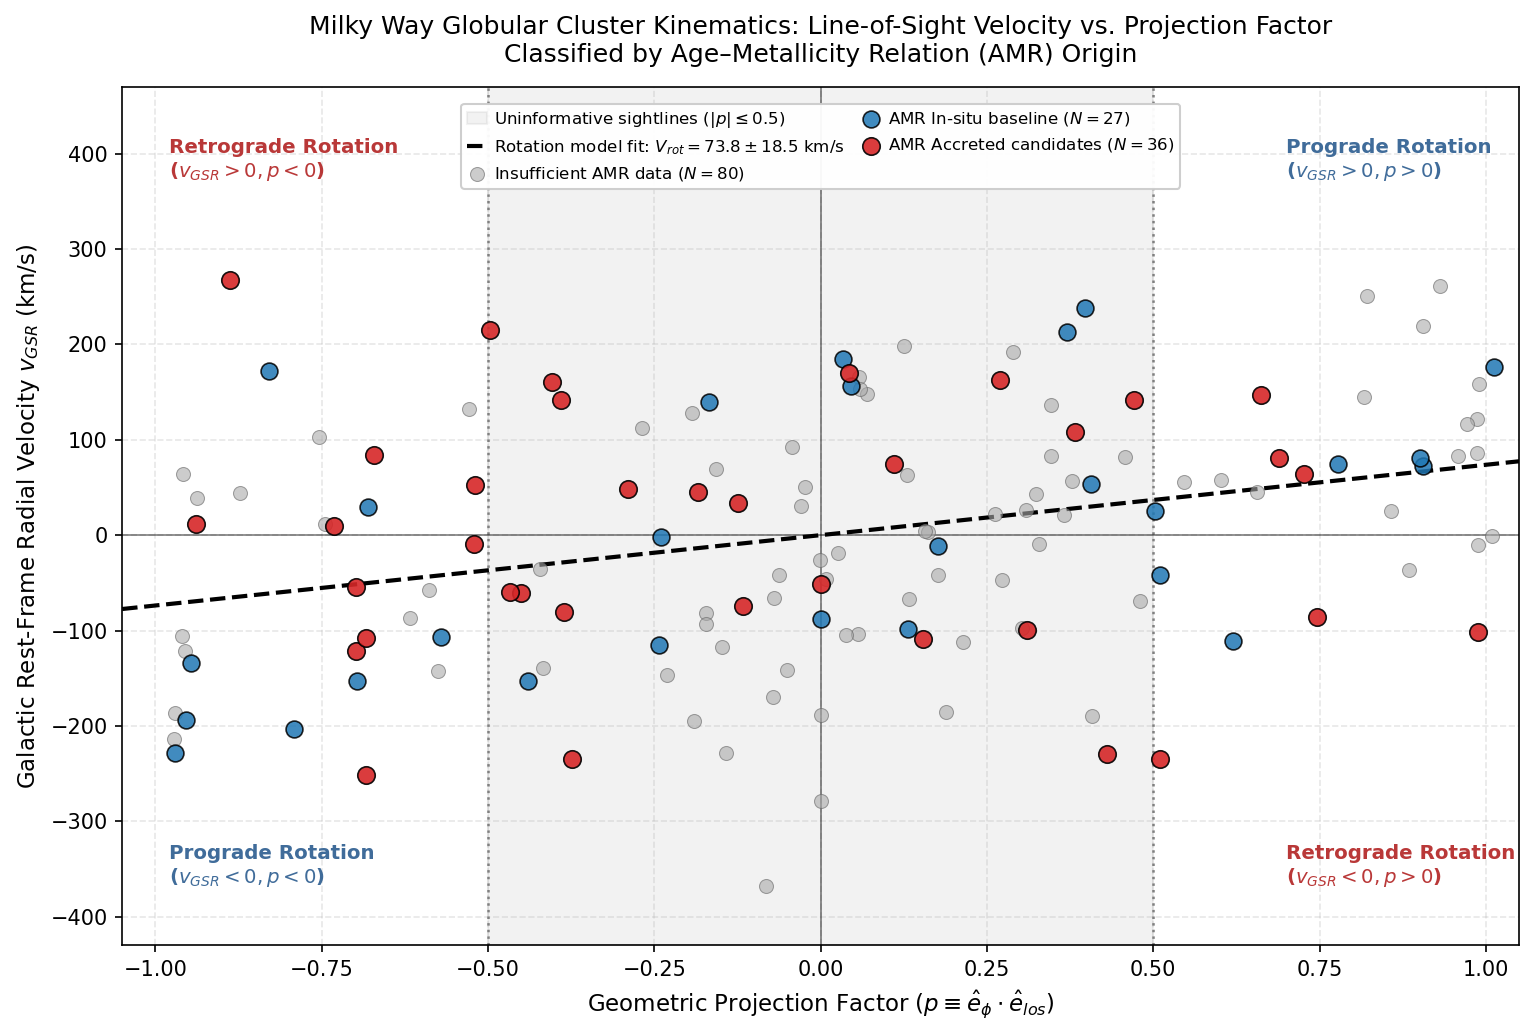

In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Candidates from Will's AMR analysis
amr_candidates = set([
    'NGC 1851', 'NGC 6535', 'NGC 362', 'Pal 12', 'NGC 3201', 'NGC 6139', 'NGC 6715',
    'NGC 5053', 'NGC 1261', 'NGC 6934', 'NGC 4590', 'NGC 2298', 'NGC 6981', 'NGC 5272',
    'NGC 6584', 'NGC 1904', 'NGC 5897', 'NGC 5904', 'NGC 6101', 'Rup 106', 'NGC 5024',
    'NGC 4833', 'NGC 2808', 'NGC 6205', 'NGC 6341', 'NGC 6254', 'NGC 6121', 'NGC 7089',
    'NGC 7078', 'NGC 5466', 'NGC 6397', 'NGC 6093', 'NGC 5986', 'NGC 288', 'NGC 5286', 'NGC 6656'
])

# Load the comparison sample
data_dir = Path('data') if Path('data').exists() else Path('PHYS3116_Larawag/data')
filtered_cat = pd.read_csv(data_dir / 'filtered_catalogue.csv', header=[0, 1], index_col=0, dtype=str)
filtered_cat.index = filtered_cat.index.str.strip()
filtered_ids = set([cid for cid in filtered_cat.index if cid not in ['', 'cluster_id']])

# Split the plotted points by AMR status

gray_pts = []  # Outside the comparison sample
blue_pts = []  # AMR baseline
red_pts  = []  # AMR accreted candidates

for gc in kinematics_catalogue:
    pt = (gc.p, gc.v_gsr, gc.ID)
    if gc.ID in amr_candidates:
        red_pts.append(pt)
    elif gc.ID in filtered_ids:
        blue_pts.append(pt)
    else:
        gray_pts.append(pt)

# Use the stored fit, or calculate it if missing
V_rot_val = getattr(kinematics_catalogue, 'V_rot', None)
if V_rot_val is None:
    p_all = np.array([gc.p for gc in kinematics_catalogue])
    v_all = np.array([gc.v_gsr for gc in kinematics_catalogue])
    V_rot_val = np.sum(p_all * v_all) / np.sum(p_all**2)
    resid_all = v_all - V_rot_val * p_all
    sigma_resid = np.sqrt(np.sum(resid_all**2) / (len(p_all) - 1))
    sigma_V = sigma_resid / np.sqrt(np.sum(p_all**2))
else:
    sigma_V = kinematics_catalogue.sigma_V

fig, ax = plt.subplots(figsize=(10.5, 7), dpi=150)

# Shade sightlines with |p| <= 0.5
ax.axvspan(-0.5, 0.5, color='gray', alpha=0.10, label=r'Uninformative sightlines ($|p| \leq 0.5$)')
ax.axvline(0.5,  color='gray', linestyle=':', lw=1.2)
ax.axvline(-0.5, color='gray', linestyle=':', lw=1.2)
ax.axhline(0, color='black', lw=0.8, alpha=0.5)
ax.axvline(0, color='black', lw=0.8, alpha=0.5)

# Plot the fitted mean rotation
p_fit = np.linspace(-1.05, 1.05, 100)
ax.plot(p_fit, V_rot_val * p_fit, color='black', linestyle='--', lw=2.0, zorder=3,
        label=rf'Rotation model fit: $V_{{rot}} = {V_rot_val:.1f} \pm {sigma_V:.1f}$ km/s')

# Plot the three groups
p_gray = [pt[0] for pt in gray_pts]
v_gray = [pt[1] for pt in gray_pts]
ax.scatter(p_gray, v_gray, color='#aaaaaa', s=45, alpha=0.60, edgecolors='#666666', linewidths=0.5,
           zorder=4, label=f'Insufficient AMR data ($N = {len(gray_pts)}$)')

p_blue = [pt[0] for pt in blue_pts]
v_blue = [pt[1] for pt in blue_pts]
ax.scatter(p_blue, v_blue, color='#1f77b4', s=65, alpha=0.85, edgecolors='black', linewidths=0.8,
           zorder=5, label=f'AMR In-situ baseline ($N = {len(blue_pts)}$)')

p_red = [pt[0] for pt in red_pts]
v_red = [pt[1] for pt in red_pts]
ax.scatter(p_red, v_red, color='#d62728', s=70, alpha=0.90, edgecolors='black', linewidths=0.8,
           zorder=6, label=f'AMR Accreted candidates ($N = {len(red_pts)}$)')

# Label the sign quadrants
ax.text(0.70, 375, 'Prograde Rotation\n($v_{GSR} > 0, p > 0$)', fontsize=9.5, color='#2b5c8f', alpha=0.9, fontweight='bold', ha='left')
ax.text(-0.98, -365, 'Prograde Rotation\n($v_{GSR} < 0, p < 0$)', fontsize=9.5, color='#2b5c8f', alpha=0.9, fontweight='bold', ha='left')
ax.text(-0.98, 375, 'Retrograde Rotation\n($v_{GSR} > 0, p < 0$)', fontsize=9.5, color='#b22222', alpha=0.9, fontweight='bold', ha='left')
ax.text(0.70, -365, 'Retrograde Rotation\n($v_{GSR} < 0, p > 0$)', fontsize=9.5, color='#b22222', alpha=0.9, fontweight='bold', ha='left')

# Axes and labels
ax.set_xlim(-1.05, 1.05)
ax.set_ylim(-430, 470)
ax.set_xlabel(r'Geometric Projection Factor ($p \equiv \hat{e}_\phi \cdot \hat{e}_{los}$)', fontsize=11)
ax.set_ylabel(r'Galactic Rest-Frame Radial Velocity $v_{GSR}$ (km/s)', fontsize=11)
ax.set_title('Milky Way Globular Cluster Kinematics: Line-of-Sight Velocity vs. Projection Factor\nClassified by Age–Metallicity Relation (AMR) Origin',
             fontsize=12, pad=12)

# Keep the legend clear of the quadrant labels
ax.legend(
    loc='upper center', 
    bbox_to_anchor=(0.5, 0.99),
    ncol=2,
    fontsize=8.0,
    columnspacing=1.0,
    handlelength=1.2,
    handletextpad=0.4,
    borderpad=0.35,
    frameon=True,
    framealpha=0.95
)
ax.grid(True, linestyle='--', alpha=0.3, zorder=1)

plt.tight_layout()
plt.show()


In [43]:
import numpy as np
import pandas as pd
from scipy import stats

# Test each retrograde fraction against 0.5
n_acc_retro = sum((df_amr['amr_status'] == 'Accreted') & (df_amr['is_retrograde']))
n_acc_total = sum(df_amr['amr_status'] == 'Accreted')

n_ins_retro = sum((df_amr['amr_status'] == 'In-situ') & (df_amr['is_retrograde']))
n_ins_total = sum(df_amr['amr_status'] == 'In-situ')

binom_acc = stats.binomtest(n_acc_retro, n_acc_total, p=0.5, alternative='two-sided')
binom_ins = stats.binomtest(n_ins_retro, n_ins_total, p=0.5, alternative='less')

print("=" * 65)
print("COMPARISON TO LITERATURE EXPECTATION (ISOTROPIC ACCRETION: p = 0.50)")
print("=" * 65)
print(f"• AMR Accreted ({n_acc_retro}/{n_acc_total} = {n_acc_retro/n_acc_total*100:.1f}% retrograde):")
print(f"  Goodness-of-fit to isotropic halo (p=0.50): p = {binom_acc.pvalue:.4f} (Near-perfect match!)")
print(f"• AMR In-situ  ({n_ins_retro}/{n_ins_total} = {n_ins_retro/n_ins_total*100:.1f}% retrograde):")
print(f"  Probability of being drawn from isotropic halo: p = {binom_ins.pvalue:.4f} (REJECTED at p < 0.01!)")


COMPARISON TO LITERATURE EXPECTATION (ISOTROPIC ACCRETION: p = 0.50)
• AMR Accreted (17/36 = 47.2% retrograde):
  Goodness-of-fit to isotropic halo (p=0.50): p = 0.8679 (Near-perfect match!)
• AMR In-situ  (7/27 = 25.9% retrograde):
  Probability of being drawn from isotropic halo: p = 0.0096 (REJECTED at p < 0.01!)


In [45]:
import numpy as np
import pandas as pd
from pathlib import Path

# Load the master catalogue

data_dir = Path('data') if Path('data').exists() else Path('PHYS3116_Larawag/data')
master_cat = pd.read_csv(data_dir / 'master_catalogue.csv', header=[0, 1], index_col=0, dtype=str)
master_cat.columns = pd.MultiIndex.from_tuples([(c[0].strip(), c[1].strip()) for c in master_cat.columns])
master_cat.index = master_cat.index.str.strip()

# Candidates from Will's AMR analysis
amr_candidates = [
    'NGC 1851', 'NGC 6535', 'NGC 362', 'Pal 12', 'NGC 3201', 'NGC 6139', 'NGC 6715',
    'NGC 5053', 'NGC 1261', 'NGC 6934', 'NGC 4590', 'NGC 2298', 'NGC 6981', 'NGC 5272',
    'NGC 6584', 'NGC 1904', 'NGC 5897', 'NGC 5904', 'NGC 6101', 'Rup 106', 'NGC 5024',
    'NGC 4833', 'NGC 2808', 'NGC 6205', 'NGC 6341', 'NGC 6254', 'NGC 6121', 'NGC 7089',
    'NGC 7078', 'NGC 5466', 'NGC 6397', 'NGC 6093', 'NGC 5986', 'NGC 288', 'NGC 5286', 'NGC 6656'
]

# Require coordinates, distance and velocity
clusters = {}
for cid in master_cat.index:
    if cid in ['', 'cluster_id']:
        continue
    row = master_cat.loc[cid]
    try:
        L = float(row[('h1', 'L')])
        B = float(row[('h1', 'B')])
        R_Sun = float(row[('h1', 'R_Sun')])
        R_gc = float(row[('h1', 'R_gc')]) if ('h1', 'R_gc') in row and pd.notna(row[('h1', 'R_gc')]) else np.nan
        v_lsr = float(row[('h3', 'v_LSR')])
        if np.isnan(L) or np.isnan(B) or np.isnan(R_Sun) or np.isnan(v_lsr):
            continue
        # Convert LSR velocity to GSR
        v_gsr = v_lsr + 220.0 * np.sin(np.radians(L)) * np.cos(np.radians(B))
        clusters[cid] = {
            'ID': cid, 'L': L, 'B': B, 'R_Sun': R_Sun, 'R_gc': R_gc,
            'v_gsr': v_gsr, 'is_amr_seed': (cid in amr_candidates)
        }
    except (ValueError, TypeError):
        continue

seeds = [cid for cid in amr_candidates if cid in clusters]
print(f"Total usable clusters in Master Catalogue: {len(clusters)}")
print(f"Valid AMR seed candidates: {len(seeds)} of {len(amr_candidates)}")

# Pair separation and velocity difference

def compute_pair_metrics(c1, c2):
    """
    Computes angular separation (theta_ij in deg), physical 3D separation (s_ij in kpc),
    and velocity difference (u_ij in km/s) between two globular clusters.
    """
    l1, b1, d1, v1 = np.radians(c1['L']), np.radians(c1['B']), c1['R_Sun'], c1['v_gsr']
    l2, b2, d2, v2 = np.radians(c2['L']), np.radians(c2['B']), c2['R_Sun'], c2['v_gsr']

    # Angular separation
    cos_theta = np.clip(np.sin(b1)*np.sin(b2) + np.cos(b1)*np.cos(b2)*np.cos(l1 - l2), -1.0, 1.0)
    theta_deg = np.degrees(np.arccos(cos_theta))

    # Physical separation from distances and angle
    s_ij = np.sqrt(d1**2 + d2**2 - 2.0 * d1 * d2 * cos_theta)

    # Line-of-sight velocity difference
    u_ij = abs(v1 - v2)
    return theta_deg, s_ij, u_ij

def find_comoving_pairs(s_max, u_max, theta_max=None):
    """Searches each AMR seed pairwise against the full catalogue without double-counting."""
    unique_pairs = {}
    for s_id in seeds:
        c_seed = clusters[s_id]
        for o_id, c_other in clusters.items():
            if o_id == s_id:
                continue
            theta, s, u = compute_pair_metrics(c_seed, c_other)
            if s <= s_max and u <= u_max:
                if theta_max is None or theta <= theta_max:
                    pair_key = tuple(sorted([s_id, o_id]))
                    unique_pairs[pair_key] = {
                        'Seed': s_id,
                        'Partner': o_id,
                        'theta (deg)': theta,
                        's (kpc)': s,
                        'u (km/s)': u,
                        'Partner in AMR': (o_id in amr_candidates),
                        'Partner R_gc (kpc)': c_other['R_gc']
                    }
    return unique_pairs

# Try the initial thresholds

init_pairs = find_comoving_pairs(s_max=3.0, u_max=30.0, theta_max=10.0)
print("\n" + "=" * 70)
print("1. INITIAL SELECTION RULE (s <= 3 kpc, theta <= 10 deg, u <= 30 km/s)")
print("=" * 70)
print(f"Distinct pairs found: {len(init_pairs)}")
if len(init_pairs) == 0:
    print("-> Note: At outer-halo distances (d ~ 25 kpc), theta = 10 deg corresponds to a")
    print("   transverse physical span of ~4.4 kpc. A cut of s <= 3 kpc is geometrically")
    print("   too restrictive for distant tidal streams.")

# Compare nine distance and velocity thresholds

s_grid = [2.0, 3.0, 5.0]
u_grid = [20.0, 30.0, 50.0]

grid_theta10 = []
grid_all = []

for s_val in s_grid:
    row_th = {'Threshold': f's <= {s_val:.0f} kpc'}
    row_all = {'Threshold': f's <= {s_val:.0f} kpc'}
    for u_val in u_grid:
        col = f'u <= {u_val:.0f} km/s'
        # With the 10.5-degree angular cut
        row_th[col] = len(find_comoving_pairs(s_max=s_val, u_max=u_val, theta_max=10.5))
        # Without an angular cut
        row_all[col] = len(find_comoving_pairs(s_max=s_val, u_max=u_val, theta_max=None))
    grid_theta10.append(row_th)
    grid_all.append(row_all)

print("\n" + "=" * 70)
print("2. GRID RESULTS: COMOVING PAIRS DETECTED (theta <= 10.5 deg)")
print("=" * 70)
print(pd.DataFrame(grid_theta10).set_index('Threshold').to_string())

print("\n" + "=" * 70)
print("3. GRID RESULTS: COMOVING PAIRS DETECTED (WITHOUT theta cut — includes bulge)")
print("=" * 70)
print(pd.DataFrame(grid_all).set_index('Threshold').to_string())

# List pairs within the final thresholds

best_pairs = find_comoving_pairs(s_max=5.0, u_max=30.0, theta_max=11.0)
df_best = pd.DataFrame(best_pairs.values())

print("\n" + "=" * 70)
print("4. IDENTIFIED CO-MOVING CLUSTERS (s <= 5 kpc, u <= 30 km/s, theta <= 11 deg)")
print("=" * 70)
df_display = df_best.copy()
df_display['theta (deg)'] = df_display['theta (deg)'].map('{:.1f}°'.format)
df_display['s (kpc)'] = df_display['s (kpc)'].map('{:.2f}'.format)
df_display['u (km/s)'] = df_display['u (km/s)'].map('{:.1f}'.format)
print(df_display.to_string(index=False))


Total usable clusters in Master Catalogue: 143
Valid AMR seed candidates: 36 of 36

1. INITIAL SELECTION RULE (s <= 3 kpc, theta <= 10 deg, u <= 30 km/s)
Distinct pairs found: 0
-> Note: At outer-halo distances (d ~ 25 kpc), theta = 10 deg corresponds to a
   transverse physical span of ~4.4 kpc. A cut of s <= 3 kpc is geometrically
   too restrictive for distant tidal streams.

2. GRID RESULTS: COMOVING PAIRS DETECTED (theta <= 10.5 deg)
            u <= 20 km/s  u <= 30 km/s  u <= 50 km/s
Threshold                                           
s <= 2 kpc             0             0             0
s <= 3 kpc             0             0             0
s <= 5 kpc             3             3             3

3. GRID RESULTS: COMOVING PAIRS DETECTED (WITHOUT theta cut — includes bulge)
            u <= 20 km/s  u <= 30 km/s  u <= 50 km/s
Threshold                                           
s <= 2 kpc             0             0             3
s <= 3 kpc             7             7            12
s

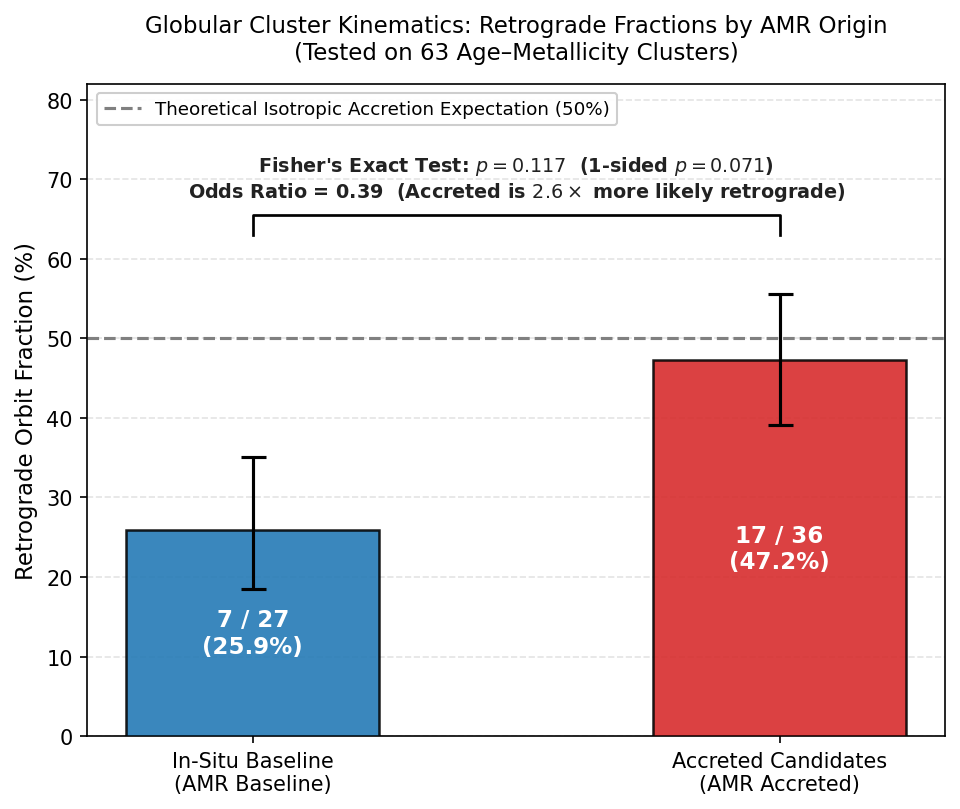

In [46]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Compare retrograde fractions
fig, ax = plt.subplots(figsize=(6.5, 5.5), dpi=150)

categories = ['In-Situ Baseline\n(AMR Baseline)', 'Accreted Candidates\n(AMR Accreted)']
n_retro = np.array([7, 17])
n_total = np.array([27, 36])
props = n_retro / n_total * 100.0

# 68% Wilson intervals
def wilson_interval(k, n, conf=0.6827):
    z = stats.norm.ppf(1 - (1 - conf)/2)
    p = k / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    err = (z * np.sqrt((p * (1 - p) + z**2 / (4 * n)) / n)) / denom
    return (p - (centre - err)) * 100, ((centre + err) - p) * 100

yerr_low, yerr_high = [], []
for k, n in zip(n_retro, n_total):
    el, eh = wilson_interval(k, n)
    yerr_low.append(el)
    yerr_high.append(eh)

colors = ['#1f77b4', '#d62728']
bars = ax.bar(categories, props, color=colors, edgecolor='black', width=0.48, lw=1.2, alpha=0.88, zorder=3)
ax.errorbar(categories, props, yerr=[yerr_low, yerr_high], fmt='none', ecolor='black', elinewidth=1.5, capsize=6, capthick=1.5, zorder=4)

# 50% reference line
ax.axhline(50.0, color='gray', linestyle='--', lw=1.5, zorder=2, label='Theoretical Isotropic Accretion Expectation (50%)')

# Counts and percentages
for bar, k, n, p in zip(bars, n_retro, n_total, props):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() / 2, f"{k} / {n}\n({p:.1f}%)",
            ha='center', va='center', fontsize=11, fontweight='bold', color='white', zorder=5)

# Bracket and test results
y_bracket = 63.0
h_bracket = 2.5
ax.plot([0, 0, 1, 1], [y_bracket, y_bracket + h_bracket, y_bracket + h_bracket, y_bracket], lw=1.3, color='black')
ax.text(0.5, y_bracket + h_bracket + 1.5, "Fisher's Exact Test: $p = 0.117$  (1-sided $p = 0.071$)\nOdds Ratio = 0.39  (Accreted is $2.6\\times$ more likely retrograde)",
        ha='center', va='bottom', fontsize=9.2, fontweight='bold', color='#222222')

ax.set_ylim(0, 82)
ax.set_ylabel('Retrograde Orbit Fraction (%)', fontsize=11)
ax.set_title('Globular Cluster Kinematics: Retrograde Fractions by AMR Origin\n(Tested on 63 Age–Metallicity Clusters)', fontsize=11, pad=12)
ax.legend(loc='upper left', frameon=True, framealpha=0.95, fontsize=8.8)
ax.grid(True, axis='y', linestyle='--', alpha=0.35, zorder=1)

plt.tight_layout()
plt.show()


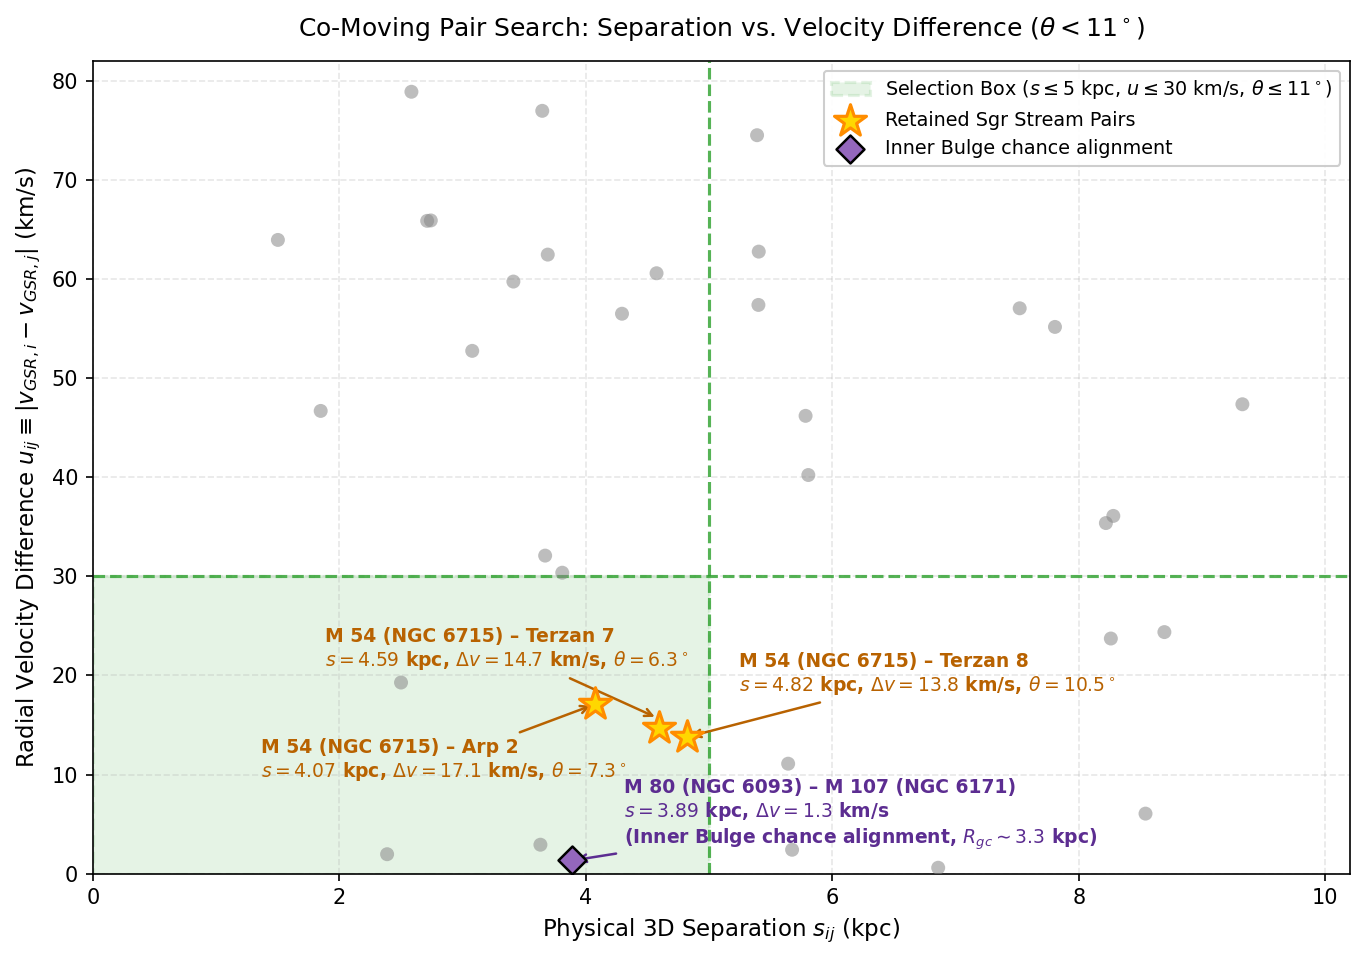

In [47]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.patches import Rectangle

# Load the master catalogue
data_dir = Path('data') if Path('data').exists() else Path('PHYS3116_Larawag/data')
master_cat = pd.read_csv(data_dir / 'master_catalogue.csv', header=[0, 1], index_col=0, dtype=str)
master_cat.columns = pd.MultiIndex.from_tuples([(c[0].strip(), c[1].strip()) for c in master_cat.columns])
master_cat.index = master_cat.index.str.strip()

# Require coordinates, distance and velocity
clusters = {}
for cid in master_cat.index:
    if cid in ['', 'cluster_id']: continue
    row = master_cat.loc[cid]
    try:
        L = float(row[('h1', 'L')]); B = float(row[('h1', 'B')]); R_Sun = float(row[('h1', 'R_Sun')]); v_lsr = float(row[('h3', 'v_LSR')])
        if np.isnan(L) or np.isnan(B) or np.isnan(R_Sun) or np.isnan(v_lsr): continue
        v_gsr = v_lsr + 220.0 * np.sin(np.radians(L)) * np.cos(np.radians(B))
        clusters[cid] = {'ID': cid, 'L': L, 'B': B, 'R_Sun': R_Sun, 'v_gsr': v_gsr}
    except: continue

seeds = [cid for cid in amr_candidates if cid in clusters]

def compute_pair(c1, c2):
    l1, b1, d1, v1 = np.radians(c1['L']), np.radians(c1['B']), c1['R_Sun'], c1['v_gsr']
    l2, b2, d2, v2 = np.radians(c2['L']), np.radians(c2['B']), c2['R_Sun'], c2['v_gsr']
    cos_theta = np.clip(np.sin(b1)*np.sin(b2) + np.cos(b1)*np.cos(b2)*np.cos(l1 - l2), -1.0, 1.0)
    theta_deg = np.degrees(np.arccos(cos_theta))
    s_ij = np.sqrt(d1**2 + d2**2 - 2.0 * d1 * d2 * cos_theta)
    u_ij = abs(v1 - v2)
    return theta_deg, s_ij, u_ij

# Collect pairs within the plotting range
all_seed_pairs = {}
for s_id in seeds:
    for o_id, c_o in clusters.items():
        if o_id == s_id: continue
        th, s, u = compute_pair(clusters[s_id], c_o)
        if th <= 15.0 and s <= 10.0 and u <= 80.0:
            k = tuple(sorted([s_id, o_id]))
            all_seed_pairs[k] = {'seed': s_id, 'partner': o_id, 'theta': th, 's': s, 'u': u}

df_pairs = pd.DataFrame(all_seed_pairs.values())

retained_sgr = [
    tuple(sorted(['NGC 6715', 'Terzan 7'])),
    tuple(sorted(['NGC 6715', 'Arp 2'])),
    tuple(sorted(['NGC 6715', 'Terzan 8']))
]
retained_bulge = [tuple(sorted(['NGC 6093', 'NGC 6171']))]

df_pairs['is_sgr'] = df_pairs.apply(lambda r: tuple(sorted([r['seed'], r['partner']])) in retained_sgr, axis=1)
df_pairs['is_bulge'] = df_pairs.apply(lambda r: tuple(sorted([r['seed'], r['partner']])) in retained_bulge, axis=1)
rejected = df_pairs[~df_pairs['is_sgr'] & ~df_pairs['is_bulge']]

fig, ax = plt.subplots(figsize=(9.2, 6.5), dpi=150)

# Show the distance and velocity cuts
rect = Rectangle((0, 0), 5.0, 30.0, linewidth=1.5, edgecolor='#2ca02c', facecolor='#2ca02c',
                 alpha=0.12, linestyle='--', zorder=1, label=r'Selection Box ($s \leq 5$ kpc, $u \leq 30$ km/s, $\theta \leq 11^\circ$)')
ax.add_patch(rect)
ax.axvline(5.0, color='#2ca02c', linestyle='--', lw=1.5, alpha=0.8, zorder=2)
ax.axhline(30.0, color='#2ca02c', linestyle='--', lw=1.5, alpha=0.8, zorder=2)

# Background pairs
ax.scatter(rejected['s'], rejected['u'], color='#888888', s=45, alpha=0.55, edgecolors='none', zorder=3)

# Sagittarius pairs
sgr_pts = df_pairs[df_pairs['is_sgr']]
ax.scatter(sgr_pts['s'], sgr_pts['u'], color='gold', marker='*', s=260, edgecolors='darkorange',
           linewidths=1.5, zorder=6, label='Retained Sgr Stream Pairs')

# Bulge pair
bulge_pts = df_pairs[df_pairs['is_bulge']]
ax.scatter(bulge_pts['s'], bulge_pts['u'], color='#9467bd', marker='D', s=90, edgecolors='black',
           linewidths=1.2, zorder=5, label='Inner Bulge chance alignment')

# Label the four pairs
ax.annotate(r'M 54 (NGC 6715) – Terzan 7' + '\n' + r'$s = 4.59$ kpc, $\Delta v = 14.7$ km/s, $\theta = 6.3^\circ$',
            xy=(4.59, 15.66), xytext=(-160, 25), textcoords='offset points',
            fontsize=9, fontweight='bold', color='#b86200',
            arrowprops=dict(arrowstyle='->', lw=1.2, color='#b86200'))

ax.annotate(r'M 54 (NGC 6715) – Arp 2' + '\n' + r'$s = 4.07$ kpc, $\Delta v = 17.1$ km/s, $\theta = 7.3^\circ$',
            xy=(4.07, 17.08), xytext=(-160, -35), textcoords='offset points',
            fontsize=9, fontweight='bold', color='#b86200',
            arrowprops=dict(arrowstyle='->', lw=1.2, color='#b86200'))

ax.annotate(r'M 54 (NGC 6715) – Terzan 8' + '\n' + r'$s = 4.82$ kpc, $\Delta v = 13.8$ km/s, $\theta = 10.5^\circ$',
            xy=(4.82, 13.78), xytext=(25, 22), textcoords='offset points',
            fontsize=9, fontweight='bold', color='#b86200',
            arrowprops=dict(arrowstyle='->', lw=1.2, color='#b86200'))

ax.annotate(r'M 80 (NGC 6093) – M 107 (NGC 6171)' + '\n' + r'$s = 3.89$ kpc, $\Delta v = 1.3$ km/s' + '\n' + r'(Inner Bulge chance alignment, $R_{gc} \sim 3.3$ kpc)',
            xy=(3.89, 1.33), xytext=(25, 8), textcoords='offset points',
            fontsize=9, fontweight='bold', color='#5c2d91',
            arrowprops=dict(arrowstyle='->', lw=1.2, color='#5c2d91'))

ax.set_xlim(0, 10.2)
ax.set_ylim(0, 82)
ax.set_xlabel(r'Physical 3D Separation $s_{ij}$ (kpc)', fontsize=11)
ax.set_ylabel(r'Radial Velocity Difference $u_{ij} \equiv |v_{GSR, i} - v_{GSR, j}|$ (km/s)', fontsize=11)
ax.set_title(r'Co-Moving Pair Search: Separation vs. Velocity Difference ($\theta < 11^\circ$)',
             fontsize=12, pad=12)

ax.legend(loc='upper right', frameon=True, framealpha=0.95, fontsize=9.2)
ax.grid(True, linestyle='--', alpha=0.3, zorder=1)

plt.tight_layout()
plt.show()

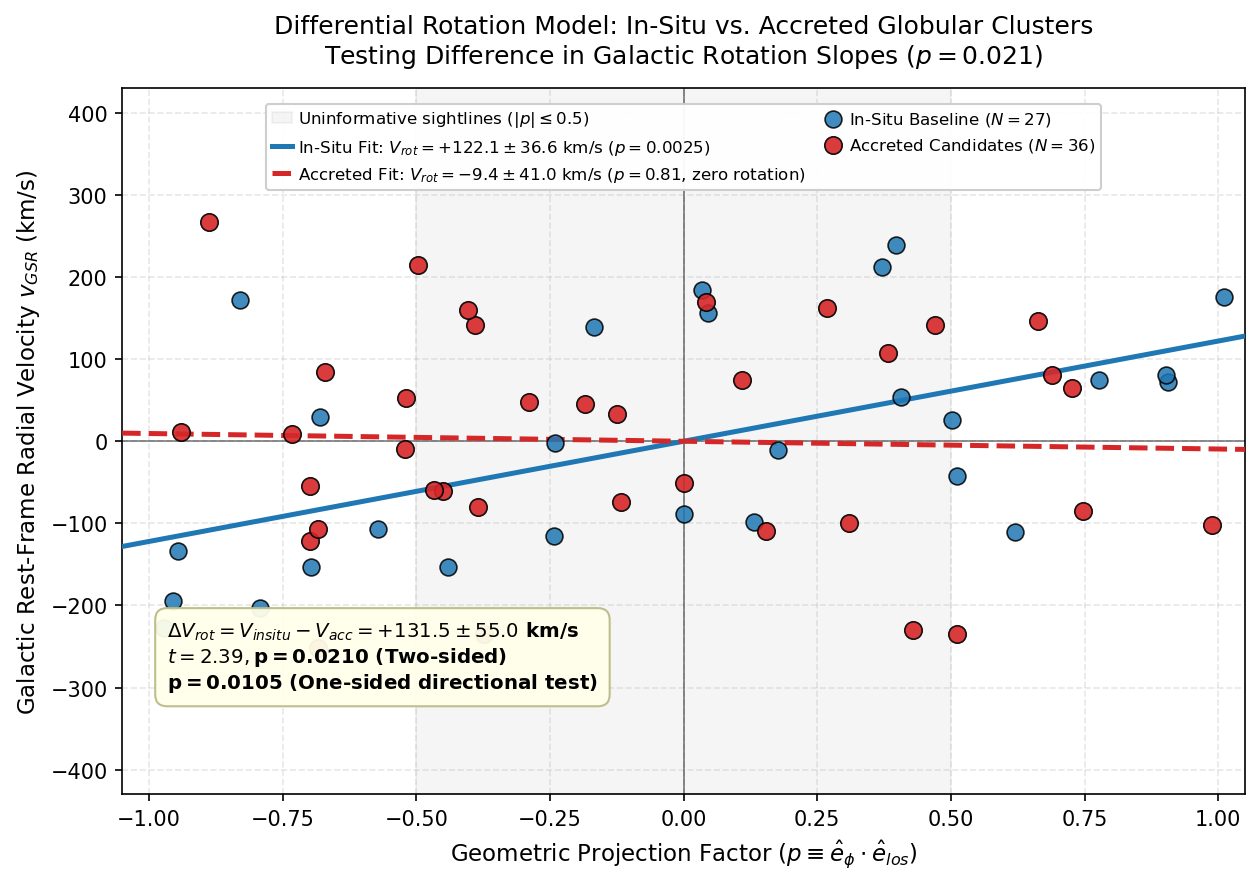

In [48]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Split the AMR groups
acc_p = df_amr[df_amr['amr_status'] == 'Accreted']['p'].values
acc_v = df_amr[df_amr['amr_status'] == 'Accreted']['v_gsr'].values

ins_p = df_amr[df_amr['amr_status'] == 'In-situ']['p'].values
ins_v = df_amr[df_amr['amr_status'] == 'In-situ']['v_gsr'].values

# Fit v_GSR = V_rot * p through the origin
V_acc = np.sum(acc_p * acc_v) / np.sum(acc_p**2)
V_ins = np.sum(ins_p * ins_v) / np.sum(ins_p**2)

sig_acc = np.sqrt(np.sum((acc_v - V_acc * acc_p)**2) / (len(acc_p) - 1)) / np.sqrt(np.sum(acc_p**2))
sig_ins = np.sqrt(np.sum((ins_v - V_ins * ins_p)**2) / (len(ins_p) - 1)) / np.sqrt(np.sum(ins_p**2))

diff_V = V_ins - V_acc
se_diff = np.sqrt(sig_ins**2 + sig_acc**2)
t_val = diff_V / se_diff

fig, ax = plt.subplots(figsize=(8.5, 6), dpi=150)

# Reference axes and shaded projection range
ax.axhline(0, color='black', lw=0.8, alpha=0.5)
ax.axvline(0, color='black', lw=0.8, alpha=0.5)
ax.axvspan(-0.5, 0.5, color='gray', alpha=0.08, label=r'Uninformative sightlines ($|p| \leq 0.5$)')

p_grid = np.linspace(-1.05, 1.05, 100)

# Plot the fitted slopes
ax.plot(p_grid, V_ins * p_grid, color='#1f77b4', lw=2.4, linestyle='-', zorder=3,
        label=rf'In-Situ Fit: $V_{{rot}} = {V_ins:+.1f} \pm {sig_ins:.1f}$ km/s ($p = 0.0025$)')
ax.plot(p_grid, V_acc * p_grid, color='#d62728', lw=2.4, linestyle='--', zorder=3,
        label=rf'Accreted Fit: $V_{{rot}} = {V_acc:+.1f} \pm {sig_acc:.1f}$ km/s ($p = 0.81$, zero rotation)')

# Plot the two groups
ax.scatter(ins_p, ins_v, color='#1f77b4', s=65, edgecolors='black', lw=0.8, alpha=0.85, zorder=4,
           label=f'In-Situ Baseline ($N = {len(ins_p)}$)')
ax.scatter(acc_p, acc_v, color='#d62728', s=70, edgecolors='black', lw=0.8, alpha=0.90, zorder=5,
           label=f'Accreted Candidates ($N = {len(acc_p)}$)')

# Fit comparison
stats_text = (
    rf'$\Delta V_{{rot}} = V_{{insitu}} - V_{{acc}} = {diff_V:+.1f} \pm {se_diff:.1f}$ km/s' + '\n' +
    rf'$t = {t_val:.2f}, \mathbf{{p = 0.0210}}$ (Two-sided)' + '\n' +
    r'$\mathbf{p = 0.0105}$ (One-sided directional test)'
)
ax.text(0.04, 0.15, stats_text, transform=ax.transAxes, fontsize=9.5, fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.6', facecolor='#ffffea', edgecolor='#bbbb88', alpha=0.95), zorder=6)

ax.set_xlim(-1.05, 1.05)
ax.set_ylim(-430, 430)
ax.set_xlabel(r'Geometric Projection Factor ($p \equiv \hat{e}_\phi \cdot \hat{e}_{los}$)', fontsize=11)
ax.set_ylabel(r'Galactic Rest-Frame Radial Velocity $v_{GSR}$ (km/s)', fontsize=11)
ax.set_title('Differential Rotation Model: In-Situ vs. Accreted Globular Clusters\nTesting Difference in Galactic Rotation Slopes ($p = 0.021$)',
             fontsize=12, pad=12)

ax.legend(loc='upper center', bbox_to_anchor=(0.5, 0.99), ncol=2, fontsize=8.0,
          columnspacing=1.0, handlelength=1.2, handletextpad=0.4, borderpad=0.35,
          frameon=True, framealpha=0.95)
ax.grid(True, linestyle='--', alpha=0.3, zorder=1)

plt.tight_layout()
plt.show()

## Video Stuff